
# Customer Churn Analysis and Retention Strategy

## Capstone Data Analytics Project

### Project Overview

Customer churn occurs when customers discontinue their subscription or stop using a company's services. Understanding churn patterns helps businesses identify customers who may leave and develop effective customer retention strategies.

This project analyzes customer data to identify churn patterns, examine factors associated with customer churn, perform statistical hypothesis testing, and recommend data-driven retention strategies.

### Project Objectives

1. Understand the customer dataset and assess data quality.
2. Calculate important business KPIs, including churn rate and retention rate.
3. Explore customer characteristics and churn patterns.
4. Analyze the relationship between tenure, monthly charges, contract type, and churn.
5. Perform statistical hypothesis testing.
6. Develop actionable business recommendations.

### Dataset Information

- Total records: 500 customers
- Total columns: 9
- Target variable: Churn
- Churn = 0: Customer retained
- Churn = 1: Customer churned

### Tools and Technologies

- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- SciPy
- Jupyter Notebook


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

# Display settings
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

# Load the cleaned dataset
df = pd.read_csv("C:\\Users\\HP\\OneDrive\\文档\\GitHub\\internship\\week_8\\capstone-churn-analysis\\data\\cleaned_data.csv")

# Display dataset information
print("Dataset Shape:", df.shape)
print("\nFirst 5 Records:")
display(df.head())

print("\nDataset Information:")
df.info()


Dataset Shape: (500, 9)

First 5 Records:


,CustomerID,Tenure,MonthlyCharges,TotalCharges,Contract,PaymentMethod,PaperlessBilling,SeniorCitizen,Churn
0,C00001,6,64,1540,One year,Credit Card,No,1,0
1,C00002,21,113,1753,Month-to-month,Electronic Check,Yes,1,0
2,C00003,27,31,1455,Two year,Credit Card,No,1,0
3,C00004,53,29,7150,Month-to-month,Electronic Check,No,1,0
4,C00005,16,185,1023,One year,Electronic Check,No,1,0



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   CustomerID        500 non-null    str  
 1   Tenure            500 non-null    int64
 2   MonthlyCharges    500 non-null    int64
 3   TotalCharges      500 non-null    int64
 4   Contract          500 non-null    str  
 5   PaymentMethod     500 non-null    str  
 6   PaperlessBilling  500 non-null    str  
 7   SeniorCitizen     500 non-null    int64
 8   Churn             500 non-null    int64
dtypes: int64(5), str(4)
memory usage: 35.3 KB


In [3]:

# Dataset dimensions
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

# Column names and data types
print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
display(df.dtypes)

# Missing values
print("\nMissing Values:")
display(df.isnull().sum())

# Duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

# Duplicate customer IDs
print("Duplicate Customer IDs:", df["CustomerID"].duplicated().sum())

# Summary statistics
print("\nNumerical Summary:")
display(df.describe())


Number of Rows: 500
Number of Columns: 9

Column Names:
['CustomerID', 'Tenure', 'MonthlyCharges', 'TotalCharges', 'Contract', 'PaymentMethod', 'PaperlessBilling', 'SeniorCitizen', 'Churn']

Data Types:


CustomerID            str
Tenure              int64
MonthlyCharges      int64
TotalCharges        int64
Contract              str
PaymentMethod         str
PaperlessBilling      str
SeniorCitizen       int64
Churn               int64
dtype: object


Missing Values:


CustomerID          0
Tenure              0
MonthlyCharges      0
TotalCharges        0
Contract            0
PaymentMethod       0
PaperlessBilling    0
SeniorCitizen       0
Churn               0
dtype: int64


Duplicate Rows: 0
Duplicate Customer IDs: 0

Numerical Summary:


,Tenure,MonthlyCharges,TotalCharges,SeniorCitizen,Churn
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,36.532000,113.636000,4237.882000,0.498000,0.106000
std,20.667057,51.799903,2260.619837,0.500497,0.308146
min,1.000000,20.000000,159.000000,0.000000,0.000000
25%,19.000000,67.000000,2237.250000,0.000000,0.000000
50%,37.000000,115.000000,4182.500000,0.000000,0.000000
75%,54.000000,158.000000,6266.750000,1.000000,0.000000
max,71.000000,199.000000,7992.000000,1.000000,1.000000


In [4]:

# Total customers
total_customers = len(df)

# Customer churn and retention
churned_customers = (df["Churn"] == 1).sum()
retained_customers = (df["Churn"] == 0).sum()

# Calculate rates
churn_rate = (churned_customers / total_customers) * 100
retention_rate = (retained_customers / total_customers) * 100

# Customer metrics
average_tenure = df["Tenure"].mean()
median_tenure = df["Tenure"].median()
average_monthly_charges = df["MonthlyCharges"].mean()
average_total_charges = df["TotalCharges"].mean()

# Display KPIs
print("CUSTOMER CHURN BUSINESS KPIs")
print("-" * 40)

print("Total Customers:", total_customers)
print("Retained Customers:", retained_customers)
print("Churned Customers:", churned_customers)

print(f"Retention Rate: {retention_rate:.2f}%")
print(f"Churn Rate: {churn_rate:.2f}%")

print(f"Average Tenure: {average_tenure:.2f} months")
print(f"Median Tenure: {median_tenure:.2f} months")
print(f"Average Monthly Charges: {average_monthly_charges:.2f}")
print(f"Average Total Charges: {average_total_charges:.2f}")


CUSTOMER CHURN BUSINESS KPIs
----------------------------------------
Total Customers: 500
Retained Customers: 447
Churned Customers: 53
Retention Rate: 89.40%
Churn Rate: 10.60%
Average Tenure: 36.53 months
Median Tenure: 37.00 months
Average Monthly Charges: 113.64
Average Total Charges: 4237.88



## 4. Exploratory Data Analysis (EDA)

### 4.1 Customer Churn Distribution

This analysis examines the distribution of retained and churned customers. It helps us understand the proportion of customers who continue using the service compared with those who leave.


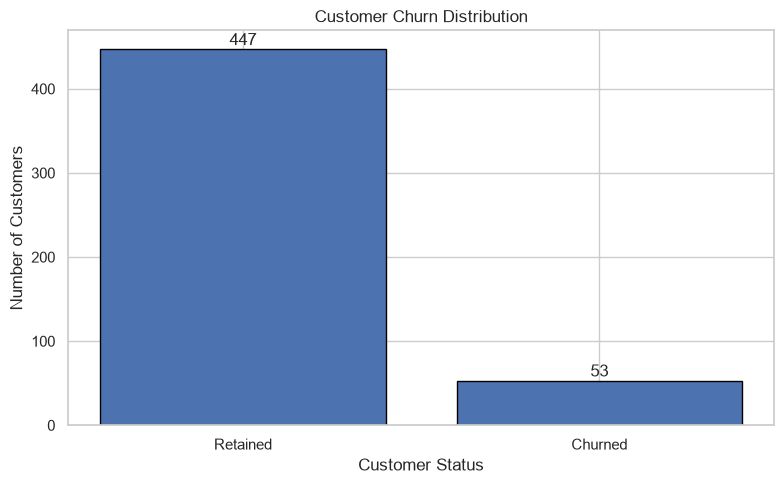

Customer Distribution:
Retained: 447 (89.40%)
Churned: 53 (10.60%)


In [5]:

# Count customers by churn status
churn_counts = df["Churn"].value_counts().sort_index()

# Create labels
labels = ["Retained", "Churned"]

# Plot
plt.figure(figsize=(8, 5))

plt.bar(
    labels,
    churn_counts.values,
    edgecolor="black"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")

for i, value in enumerate(churn_counts.values):
    plt.text(i, value + 5, str(value), ha="center")

plt.tight_layout()
plt.show()

# Display percentages
print("Customer Distribution:")
print(f"Retained: {retained_customers} ({retention_rate:.2f}%)")
print(f"Churned: {churned_customers} ({churn_rate:.2f}%)")



### 4.2 Customer Tenure Distribution

Tenure represents the number of months a customer has stayed with the company. This analysis groups customers into tenure ranges to understand the distribution of customer loyalty over time.


Customer Tenure Groups:


TenureGroup
(0, 15]      110
(15, 30]      94
(30, 45]      99
(45, 60]     118
(60, 100]     79
Name: count, dtype: int64

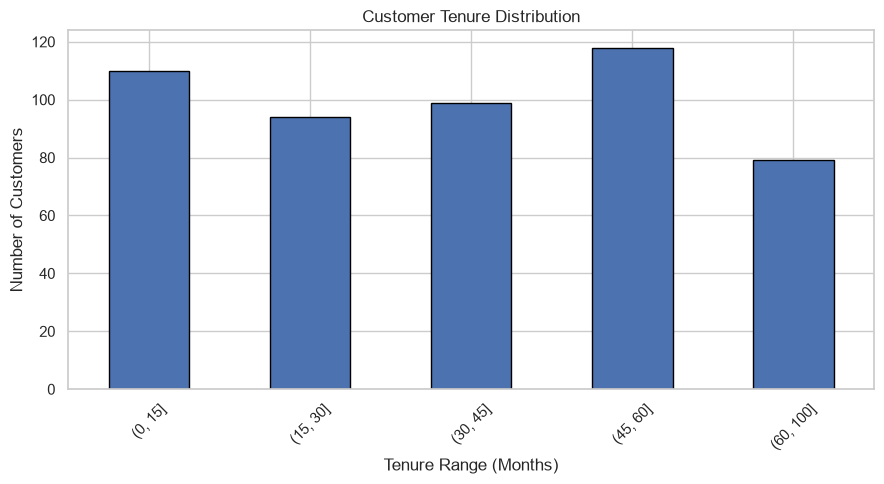

In [6]:

# Create tenure groups
tenure_bins = [0, 15, 30, 45, 60, 100]

df["TenureGroup"] = pd.cut(
    df["Tenure"],
    bins=tenure_bins
)

# Count customers in each group
tenure_counts = df["TenureGroup"].value_counts().sort_index()

# Display results
print("Customer Tenure Groups:")
display(tenure_counts)

# Visualize tenure distribution
plt.figure(figsize=(9, 5))

tenure_counts.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Customer Tenure Distribution")
plt.xlabel("Tenure Range (Months)")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()



### 4.3 Contract Type Analysis

This analysis examines the distribution of customer contract types and compares churn rates across different contracts.

The objective is to identify which contract category has the highest observed customer churn rate.


Contract Distribution:


Contract
One year          186
Month-to-month    170
Two year          144
Name: count, dtype: int64

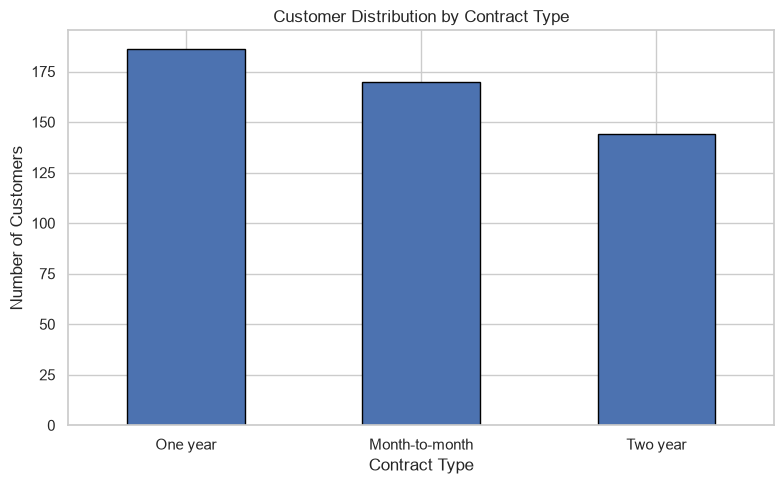


Churn Rate by Contract Type:


Contract
Month-to-month    20.59
One year           4.30
Two year           6.94
Name: Churn, dtype: float64

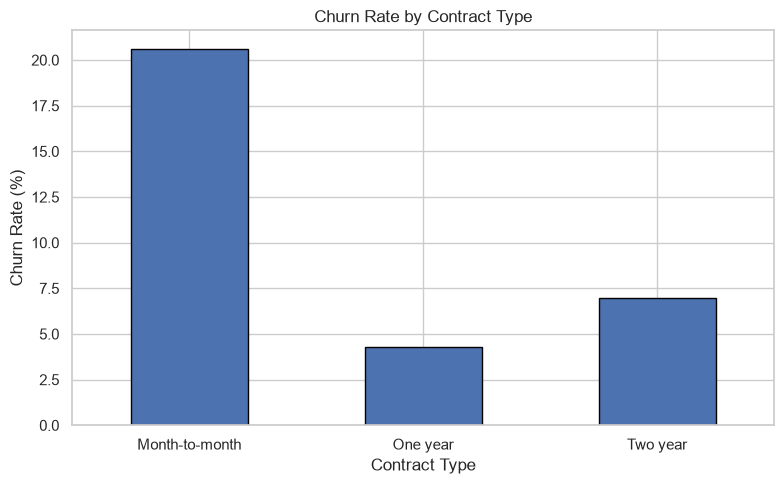

In [7]:

# Contract distribution
contract_counts = df["Contract"].value_counts()

print("Contract Distribution:")
display(contract_counts)

# Plot contract distribution
plt.figure(figsize=(8, 5))

contract_counts.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Customer Distribution by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

# Calculate churn rate by contract
contract_churn_rate = (
    df.groupby("Contract")["Churn"].mean() * 100
)

print("\nChurn Rate by Contract Type:")
display(contract_churn_rate.round(2))

# Plot contract-wise churn rate
plt.figure(figsize=(8, 5))

contract_churn_rate.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()



### 4.4 Monthly Charges and Payment Method Analysis

This section examines customer monthly charges and compares churn rates across payment methods.

The objective is to identify whether customer charges and payment categories show any meaningful patterns associated with churn.


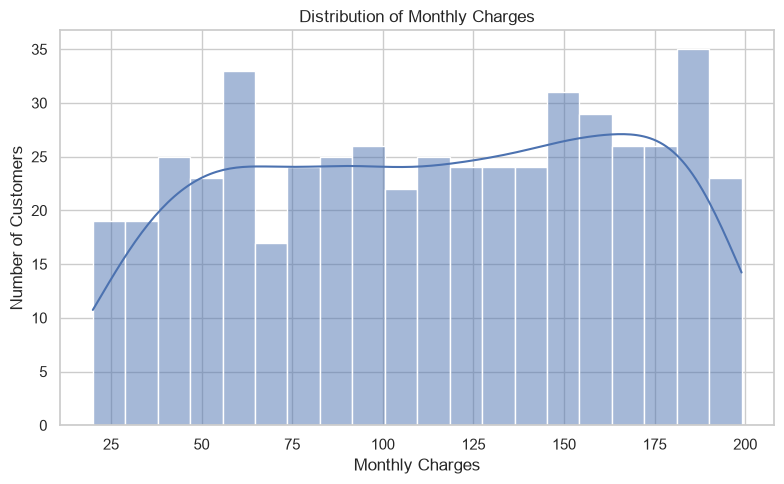

Average Monthly Charges by Customer Status:
Retained: 111.72
Churned: 129.77

Payment Method Distribution:


PaymentMethod
Credit Card         178
Electronic Check    163
Bank Transfer       159
Name: count, dtype: int64


Churn Rate by Payment Method:


PaymentMethod
Bank Transfer        6.92
Credit Card         13.48
Electronic Check    11.04
Name: Churn, dtype: float64

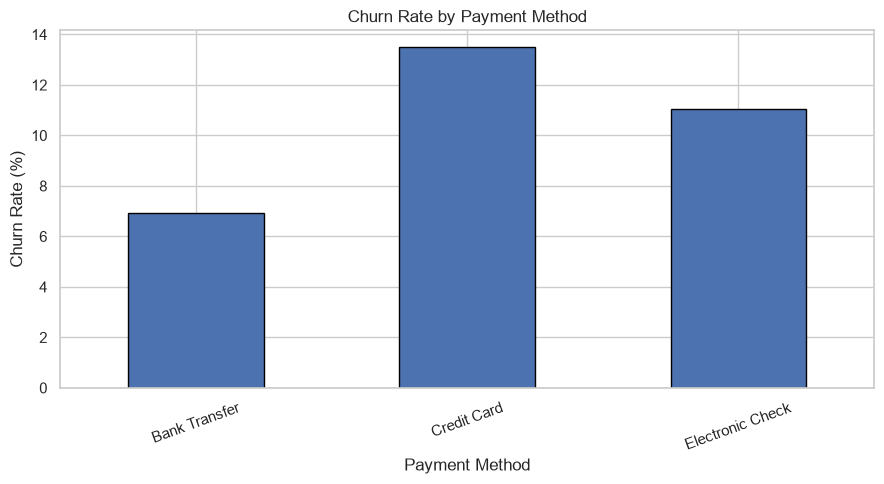

In [9]:

# Monthly charges distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    df["MonthlyCharges"],
    bins=20,
    kde=True
)

plt.title("Distribution of Monthly Charges")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

# Average monthly charges by churn status
charges_by_churn = df.groupby("Churn")["MonthlyCharges"].mean()

print("Average Monthly Charges by Customer Status:")
print("Retained:", round(charges_by_churn.loc[0], 2))
print("Churned:", round(charges_by_churn.loc[1], 2))

# Payment method distribution
payment_counts = df["PaymentMethod"].value_counts()

print("\nPayment Method Distribution:")
display(payment_counts)

# Calculate churn rate by payment method
payment_churn_rate = (
    df.groupby("PaymentMethod")["Churn"].mean() * 100
)

print("\nChurn Rate by Payment Method:")
display(payment_churn_rate.round(2))

# Visualize payment method churn rates
plt.figure(figsize=(9, 5))

payment_churn_rate.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()



### 4.5 Customer Tenure and Correlation Analysis

This section compares customer tenure between retained and churned customers. It also examines correlations between numerical variables to identify relationships with customer churn.


Average Tenure by Customer Status:
Retained: 40.15 months
Churned: 6.0 months


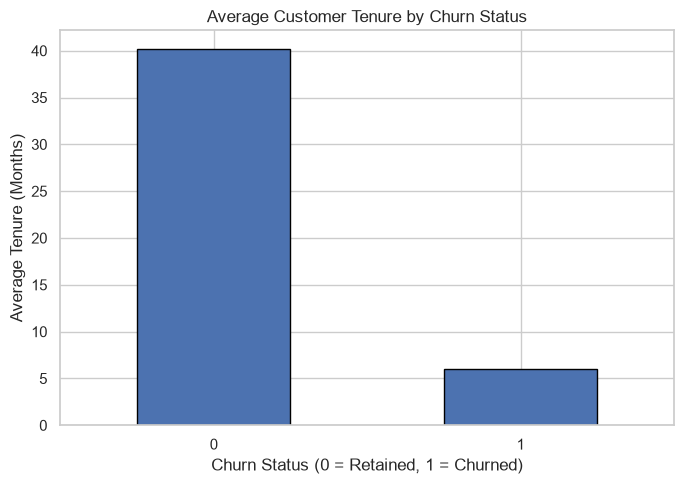


Correlation Matrix:


,Tenure,MonthlyCharges,TotalCharges,Churn
Tenure,1.00,-0.06,-0.01,-0.51
MonthlyCharges,-0.06,1.00,-0.04,0.11
TotalCharges,-0.01,-0.04,1.00,0.00
Churn,-0.51,0.11,0.00,1.00


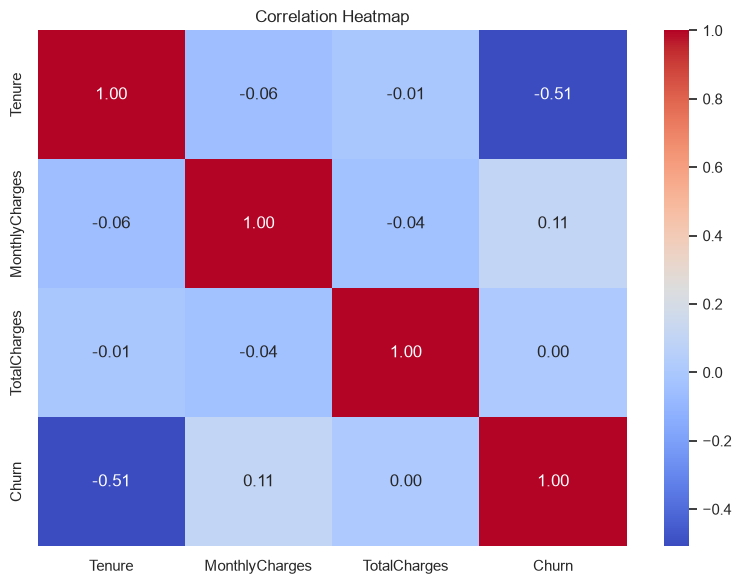

In [11]:

# Average tenure by churn status
tenure_by_churn = df.groupby("Churn")["Tenure"].mean()

print("Average Tenure by Customer Status:")
print("Retained:", round(tenure_by_churn.loc[0], 2), "months")
print("Churned:", round(tenure_by_churn.loc[1], 2), "months")

# Visualize average tenure
plt.figure(figsize=(7, 5))

tenure_by_churn.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Average Customer Tenure by Churn Status")
plt.xlabel("Churn Status (0 = Retained, 1 = Churned)")
plt.ylabel("Average Tenure (Months)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

# Correlation analysis
numeric_df = df[
    ["Tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

correlation_matrix = numeric_df.corr()

print("\nCorrelation Matrix:")
display(correlation_matrix.round(2))

# Correlation heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.tight_layout()
plt.show()



## 5. Statistical Hypothesis Testing

Statistical hypothesis testing helps determine whether observed differences or relationships in the dataset are statistically significant.

The significance level for all tests is set to 0.05.

### Hypotheses

- Null Hypothesis (H₀): No significant difference or association exists.
- Alternative Hypothesis (H₁): A significant difference or association exists.

### Decision Rule

- If p-value < 0.05: Reject H₀.
- If p-value ≥ 0.05: Fail to reject H₀.


In [13]:

# Significance level
alpha = 0.05

# Separate customers by churn status
retained = df[df["Churn"] == 0]
churned = df[df["Churn"] == 1]

# Test 1: Tenure vs Churn
tenure_test = stats.ttest_ind(
    retained["Tenure"],
    churned["Tenure"],
    equal_var=False
)

p_value_tenure = tenure_test.pvalue

# Test 2: Monthly Charges vs Churn
charges_test = stats.ttest_ind(
    retained["MonthlyCharges"],
    churned["MonthlyCharges"],
    equal_var=False
)

p_value_charges = charges_test.pvalue

# Test 3: Contract Type vs Churn
contract_table = pd.crosstab(
    df["Contract"],
    df["Churn"]
)

chi2_stat, p_value_contract, dof, expected = (
    stats.chi2_contingency(contract_table)
)

# Display results
results = pd.DataFrame({
    "Analysis": [
        "Tenure vs Churn",
        "Monthly Charges vs Churn",
        "Contract Type vs Churn"
    ],
    "Test Used": [
        "Welch's Independent Samples t-test",
        "Welch's Independent Samples t-test",
        "Chi-square Test of Independence"
    ],
    "P-value": [
        p_value_tenure,
        p_value_charges,
        p_value_contract
    ]
})

results["Decision"] = np.where(
    results["P-value"] < alpha,
    "Reject H0",
    "Fail to reject H0"
)

print("STATISTICAL TEST RESULTS")
display(results)


STATISTICAL TEST RESULTS


,Analysis,Test Used,P-value,Decision
0,Tenure vs Churn,Welch's Independent Samples t-test,8.982326e-130,Reject H0
1,Monthly Charges vs Churn,Welch's Independent Samples t-test,1.007920e-02,Reject H0
2,Contract Type vs Churn,Chi-square Test of Independence,9.587354e-07,Reject H0



### 5.1 Interpretation of Statistical Results

**1. Tenure vs Churn**

- Test used: Welch's Independent Samples t-test.
- P-value: 8.982326e-130.
- Decision: Reject H₀.
- Interpretation: There is a statistically significant difference in average tenure between retained and churned customers. Churned customers have considerably shorter average tenure.

**2. Monthly Charges vs Churn**

- Test used: Welch's Independent Samples t-test.
- P-value: 0.010079.
- Decision: Reject H₀.
- Interpretation: There is a statistically significant difference in average monthly charges between retained and churned customers. Churned customers have higher average monthly charges.

**3. Contract Type vs Churn**

- Test used: Chi-square Test of Independence.
- P-value: 9.587354e-07.
- Decision: Reject H₀.
- Interpretation: There is a statistically significant association between contract type and customer churn. Month-to-month customers have the highest observed churn rate.

### 5.2 Statistical Analysis Conclusion

All three tests produced p-values below the 0.05 significance level. Therefore, the null hypotheses were rejected.

The findings indicate that customer tenure, monthly charges, and contract type are significantly associated with customer churn in this dataset.

Statistical significance does not establish causation.



## 6. Business Recommendations

Based on the exploratory data analysis and statistical findings, the following strategies are recommended:

### 1. Focus on Early Customer Retention
Churned customers have an average tenure of only 6 months, compared with 40.15 months for retained customers.

**Recommendation:** Introduce customer onboarding support, early engagement campaigns, and follow-up communication during the initial months.

### 2. Encourage Long-Term Contracts
Month-to-month customers have the highest observed churn rate at 20.59%.

**Recommendation:** Offer suitable incentives, loyalty benefits, and discounts to encourage customers to consider annual or longer-term contracts.

### 3. Review Monthly Pricing
Churned customers have higher average monthly charges (129.77) than retained customers (111.72).

**Recommendation:** Review pricing plans, communicate plan value clearly, and evaluate suitable packages for higher-paying customers.

### 4. Investigate Payment Method Patterns
Credit Card users have the highest observed churn rate at 13.48%.

**Recommendation:** Investigate whether payment experience, customer characteristics, or other factors explain this pattern before introducing payment-related changes.

### 5. Develop a Customer Retention Monitoring System
Monitor customer churn rate, retention rate, tenure, contract type, and monthly charges regularly.

**Recommendation:** Build a dashboard to track customer KPIs and identify customer groups that may need additional attention.

## 7. Business Impact

Implementing these recommendations could help the company:

- Improve customer retention.
- Identify potentially high-risk customer segments.
- Strengthen customer engagement.
- Improve pricing and contract strategies.
- Support data-driven business decisions.

These recommendations should be tested and monitored before being adopted as company-wide policies.



## 8. Project Conclusion

This capstone project analyzed customer churn patterns using a dataset containing 500 customer records and 9 attributes.

The analysis identified an overall churn rate of 10.60% and a retention rate of 89.40%.

Exploratory data analysis revealed that churned customers had substantially shorter average tenure and higher average monthly charges than retained customers. Month-to-month contract customers also showed the highest observed churn rate.

Three statistical tests were conducted:
- Welch's t-test for tenure and churn.
- Welch's t-test for monthly charges and churn.
- Chi-square test for contract type and churn.

All three tests showed statistically significant results at the 0.05 significance level.

The project demonstrates how Python-based data analytics and statistical methods can help businesses understand customer behavior and develop customer retention strategies.

## 9. Project Limitations

1. The analysis uses only 500 customer records.
2. The dataset contains limited customer attributes.
3. The analysis identifies associations but does not establish causation.
4. The findings may not represent the behavior of all customers or businesses.
5. No predictive machine learning model was developed in this project.

## 10. Future Scope

1. Develop a machine learning model to predict customer churn.
2. Identify high-risk customers using predictive analytics.
3. Build an interactive Power BI or Python dashboard.
4. Perform deeper customer segmentation.
5. Evaluate retention strategies using additional customer data.

## 11. Final Outcome

The project successfully demonstrates the application of data cleaning, exploratory data analysis, statistical hypothesis testing, and business interpretation to a customer churn problem.

**End of Capstone Analysis.**
